# Dataset overview: GZ DECaLS (GZD5) splits and training subsets

Tables and figures describing the data used in the augmentation study, with LaTeX versions for the paper (`results/tables/dataset/*.tex`).

**Splits.** The study uses three **fixed** splits of GZD5 (`decals_split_{train,val,test}.parquet`), identical for every run. Full-data runs train on all of train; every run selects its checkpoint on validation and is scored on test.

**Training subsets (sweep).** The training-set-size sweep uses **fixed, nested** random subsets of the training split. `train.py` draws one permutation of the training indices with a fixed seed (`--subset-seed 0`) and keeps the first ⌊f·N⌉ galaxies. So:
- every experiment and every training seed at a given fraction sees *exactly the same* galaxies;
- smaller subsets are contained in larger ones (1% ⊂ 5% ⊂ 20% ⊂ 50% ⊂ 100%).

Differences between runs therefore come from the augmentation and the training seed, never from a different draw of data. Section 3 recomputes the subsets and checks them against the `train_subset.npy` saved by every sweep run. (Sweep runs select their checkpoint on a fixed random subset of 5,000 validation galaxies and are scored on the full test split.)

**"How many of each galaxy".** GZD5 labels are volunteer vote counts per answer, not classes, and the decision tree means later questions are only asked for some galaxies. For the tables, a galaxy *counts for a question* if the question received at least `MIN_VOTES` votes. Its *label* is the **majority answer** (the answer with the most votes; ties go to the first answer in the schema). Counts and percentages are over the galaxies that count for that question.

In [1]:
import os
# ---- config
from pathlib import Path

DATA_DIR    = Path(os.environ.get("GZD5_DATA_DIR", Path.home() / "project_data" / "aa_gz_decals"))
SWEEP_ROOT  = Path("runs/sweep")              # used only to verify the saved subsets
SUBSET_SEED = 0                               # train.py --subset-seed
FRACTIONS   = [0.01, 0.05, 0.2, 0.5]          # sweep fractions (100% = the full training split)
MIN_VOTES   = 1                               # a question counts for a galaxy with >= this many votes
TABLE_DIR   = Path("results/tables/dataset")
FIG_DIR     = Path("results/figures/dataset")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from data.dataset import DECaLSDataset
from task.gdz_5_schema import GZD5_QUESTIONS

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})

SPLITS = ["train", "val", "test"]
# the same dataset class as training: identical row filtering and vote-count columns
DS = {s: DECaLSDataset(parquet_path=DATA_DIR / f"decals_split_{s}.parquet", data_root=DATA_DIR) for s in SPLITS}
N = {s: len(DS[s]) for s in SPLITS}

QLABEL = {q.name: q.name.replace("_", " ") for q in GZD5_QUESTIONS}
num = lambda n: f"{int(n):,}".replace(",", "{,}")          # LaTeX thousands separator, for numbers only
ALABEL = lambda a: a.replace("-", " ")


def votes(ds, q):
    """(n_galaxies, n_answers) vote counts of question q, in schema answer order."""
    return ds.targets[:, ds._target_slices[q.name]]


# no galaxy may appear in two splits
paths = {s: set(DS[s].paths) for s in SPLITS}
overlap = {f"{a}∩{b}": len(paths[a] & paths[b]) for i, a in enumerate(SPLITS) for b in SPLITS[i + 1:]}
assert not any(overlap.values()), f"splits overlap: {overlap}"
print("galaxies per split:", N, "| total", sum(N.values()), "| overlaps:", overlap)

galaxies per split: {'train': 199664, 'val': 24958, 'test': 24959} | total 249581 | overlaps: {'train∩val': 0, 'train∩test': 0, 'val∩test': 0}


## 1. Split sizes

In [3]:
total = sum(N.values())
sf = GZD5_QUESTIONS[0]                                  # smooth_or_featured: asked of every galaxy
size_rows = []
for s in SPLITS:
    v = votes(DS[s], sf).sum(1)
    size_rows.append({"split": s, "galaxies": N[s], "share": N[s] / total,
                      "median votes (first question)": float(np.median(v)), "mean votes (first question)": float(v.mean())})
size_df = pd.DataFrame(size_rows)
size_df.loc[len(size_df)] = {"split": "total", "galaxies": total, "share": 1.0,
                             "median votes (first question)": np.nan, "mean votes (first question)": np.nan}
display(size_df.style.format({"share": "{:.1%}", "median votes (first question)": "{:.0f}",
                              "mean votes (first question)": "{:.1f}"}, na_rep="").hide(axis="index"))

def latex_split_sizes(df):
    lines = [r"\begin{table}", r"\centering",
             r"\caption{GZ DECaLS (GZD5) splits used in this work. The splits are fixed for every run. "
             r"Votes are the number of volunteer classifications of the first question.}",
             r"\label{tab:splits}", r"\begin{tabular}{lrrr}", r"\toprule",
             r"Split & Galaxies & Share & Median votes \\", r"\midrule"]
    for _, r in df.iterrows():
        if r["split"] == "total":
            lines += [r"\midrule", f"Total & {num(r['galaxies'])} & 100\\% & -- \\\\"]
        else:
            lines.append(f"{r['split'].capitalize()} & {num(r['galaxies'])} & {100 * r['share']:.1f}\\% & "
                         f"{r['median votes (first question)']:.0f} \\\\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    return "\n".join(lines)

tex = latex_split_sizes(size_df)
(TABLE_DIR / "splits.tex").write_text(tex + "\n")
size_df.to_csv(TABLE_DIR / "splits.csv", index=False)
print(tex)

split,galaxies,share,median votes (first question),mean votes (first question)
train,199664,80.0%,5,15.4
val,24958,10.0%,5,15.1
test,24959,10.0%,5,15.4
total,249581,100.0%,,


\begin{table}
\centering
\caption{GZ DECaLS (GZD5) splits used in this work. The splits are fixed for every run. Votes are the number of volunteer classifications of the first question.}
\label{tab:splits}
\begin{tabular}{lrrr}
\toprule
Split & Galaxies & Share & Median votes \\
\midrule
Train & 199{,}664 & 80.0\% & 5 \\
Val & 24{,}958 & 10.0\% & 5 \\
Test & 24{,}959 & 10.0\% & 5 \\
\midrule
Total & 249{,}581 & 100\% & -- \\
\bottomrule
\end{tabular}
\end{table}


## 2. Morphology counts per split

For each question: the number of galaxies whose majority answer is each answer, per split, with the percentage of the galaxies that count for that question. The bottom line of each question block gives that number (galaxies with ≥ `MIN_VOTES` votes).

In [4]:
def majority_counts(ds, idx=None):
    """{question: (n_answered, counts per answer)} for the galaxies `idx` (default all)."""
    out = {}
    for q in GZD5_QUESTIONS:
        v = votes(ds, q) if idx is None else votes(ds, q)[idx]
        asked = v.sum(1) >= MIN_VOTES
        winner = v[asked].argmax(1)
        out[q.name] = (int(asked.sum()), np.bincount(winner, minlength=len(q.answers)))
    return out


def counts_table(groups: dict):
    """Long table: question, answer, and n / % for every group (split or subset)."""
    rows = []
    for q in GZD5_QUESTIONS:
        for k, a in enumerate(q.answers):
            r = {"question": q.name, "answer": a}
            for g, mc in groups.items():
                n_q, c = mc[q.name]
                r[f"{g} n"] = int(c[k])
                r[f"{g} %"] = 100 * c[k] / n_q if n_q else np.nan
            rows.append(r)
        r = {"question": q.name, "answer": "(galaxies counted)"}
        for g, mc in groups.items():
            r[f"{g} n"], r[f"{g} %"] = mc[q.name][0], np.nan
        rows.append(r)
    return pd.DataFrame(rows)


SPLIT_COUNTS = {s: majority_counts(DS[s]) for s in SPLITS}
split_table = counts_table(SPLIT_COUNTS)
display(split_table.style.format({c: "{:,.0f}" for c in split_table if c.endswith(" n")} |
                                 {c: "{:.1f}" for c in split_table if c.endswith(" %")}, na_rep="").hide(axis="index"))
split_table.to_csv(TABLE_DIR / "morphology_per_split.csv", index=False)

# largest difference in answer share between splits (are the splits representative of each other?)
share_cols = [f"{s} %" for s in SPLITS]
answers_only = split_table[split_table["answer"] != "(galaxies counted)"]
gap = answers_only[share_cols].max(axis=1) - answers_only[share_cols].min(axis=1)
print(f"largest difference in answer share between splits: {gap.max():.2f} percentage points "
      f"({answers_only.loc[gap.idxmax(), 'question']}: {answers_only.loc[gap.idxmax(), 'answer']})")

question,answer,train n,train %,val n,val %,test n,test %
smooth_or_featured,smooth,"137,355",68.8,"17,169",68.8,"17,170",68.8
smooth_or_featured,featured-or-disk,"59,168",29.6,"7,396",29.6,"7,397",29.6
smooth_or_featured,artifact,"3,141",1.6,393,1.6,392,1.6
smooth_or_featured,(galaxies counted),"199,664",,"24,958",,"24,959",
disk_edge_on,yes,"36,476",23.6,"4,465",23.2,"4,571",23.8
disk_edge_on,no,"118,023",76.4,"14,786",76.8,"14,599",76.2
disk_edge_on,(galaxies counted),"154,499",,"19,251",,"19,170",
has_spiral_arms,yes,"57,824",43.2,"7,202",42.9,"7,119",42.9
has_spiral_arms,no,"76,045",56.8,"9,591",57.1,"9,479",57.1
has_spiral_arms,(galaxies counted),"133,869",,"16,793",,"16,598",


largest difference in answer share between splits: 1.08 percentage points (edge_on_bulge: none)


In [5]:
def latex_counts(table, groups, caption, label, group_titles=None):
    """booktabs table: Question | Answer | n (%) per group; one block per question."""
    group_titles = group_titles or {g: g for g in groups}
    cols = "ll" + "r" * len(groups)
    head = " & ".join(["Question", "Majority answer"] + [group_titles[g] for g in groups]) + r" \\"
    lines = [r"\begin{table*}", r"\centering", r"\small", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
             f"\\begin{{tabular}}{{{cols}}}", r"\toprule", head, r"\midrule"]
    for qi, q in enumerate(GZD5_QUESTIONS):
        block = table[table["question"] == q.name]
        for k, (_, r) in enumerate(block.iterrows()):
            if r["answer"] == "(galaxies counted)":
                cells = [f"\\textit{{{num(r[f'{g} n'])}}}" for g in groups]
                lines.append(" & ".join(["", r"\textit{counted}"] + cells) + r" \\")
                continue
            qname = QLABEL[q.name] if k == 0 else ""
            cells = [f"{num(r[f'{g} n'])} ({r[f'{g} %']:.1f}\\%)" for g in groups]
            lines.append(" & ".join([qname, ALABEL(r["answer"])] + cells) + r" \\")
        if qi < len(GZD5_QUESTIONS) - 1:
            lines.append(r"\midrule")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table*}"]
    return "\n".join(lines)


tex = latex_counts(split_table, SPLITS,
                   caption=("Majority-vote morphology of the GZD5 splits. For each decision-tree question, the number "
                            f"of galaxies whose most-voted answer is the given answer, and its share of the galaxies "
                            f"with at least {MIN_VOTES} vote(s) for that question (\\textit{{counted}})."),
                   label="tab:morphology_splits", group_titles={s: s.capitalize() for s in SPLITS})
(TABLE_DIR / "morphology_per_split.tex").write_text(tex + "\n")
print(tex[:1500] + "\n...")

\begin{table*}
\centering
\small
\caption{Majority-vote morphology of the GZD5 splits. For each decision-tree question, the number of galaxies whose most-voted answer is the given answer, and its share of the galaxies with at least 1 vote(s) for that question (\textit{counted}).}
\label{tab:morphology_splits}
\begin{tabular}{llrrr}
\toprule
Question & Majority answer & Train & Val & Test \\
\midrule
smooth or featured & smooth & 137{,}355 (68.8\%) & 17{,}169 (68.8\%) & 17{,}170 (68.8\%) \\
 & featured or disk & 59{,}168 (29.6\%) & 7{,}396 (29.6\%) & 7{,}397 (29.6\%) \\
 & artifact & 3{,}141 (1.6\%) & 393 (1.6\%) & 392 (1.6\%) \\
 & \textit{counted} & \textit{199{,}664} & \textit{24{,}958} & \textit{24{,}959} \\
\midrule
disk edge on & yes & 36{,}476 (23.6\%) & 4{,}465 (23.2\%) & 4{,}571 (23.8\%) \\
 & no & 118{,}023 (76.4\%) & 14{,}786 (76.8\%) & 14{,}599 (76.2\%) \\
 & \textit{counted} & \textit{154{,}499} & \textit{19{,}251} & \textit{19{,}170} \\
\midrule
has spiral arms & yes & 57{

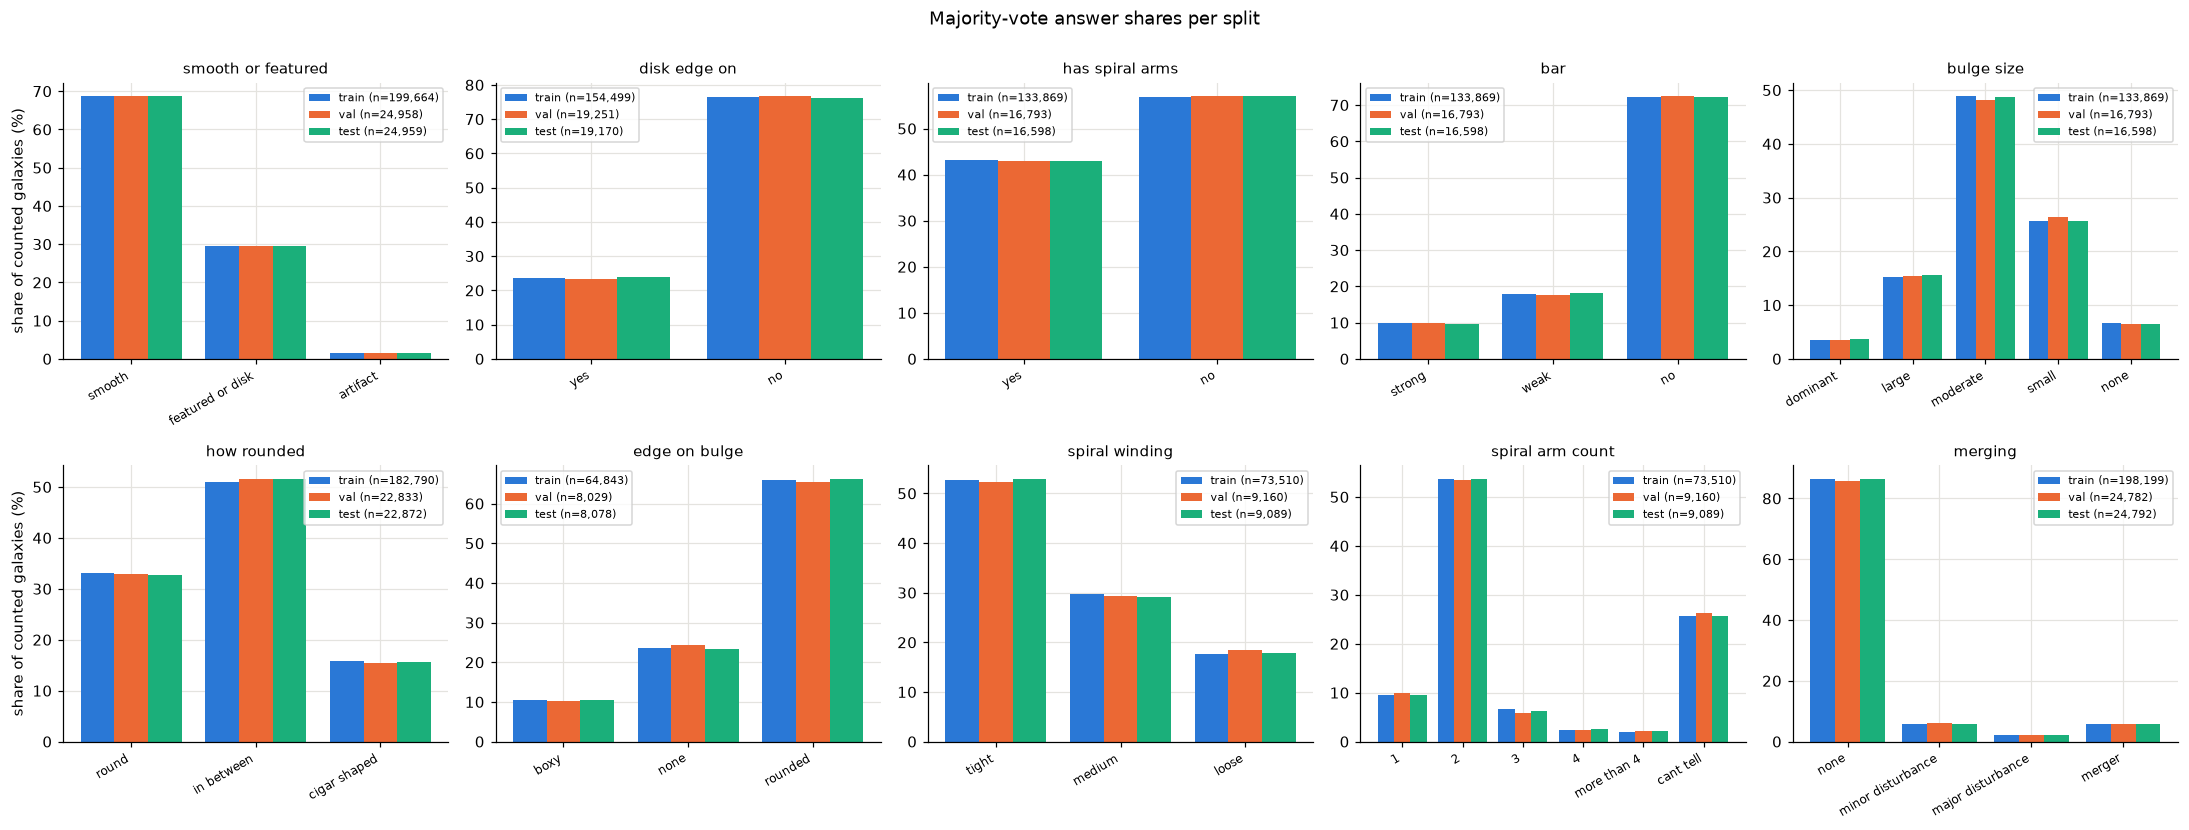

In [6]:
# figure: answer shares per split, one panel per question
COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, q in zip(axes.flat, GZD5_QUESTIONS):
    x = np.arange(len(q.answers))
    w = 0.27
    for i, s in enumerate(SPLITS):
        n_q, c = SPLIT_COUNTS[s][q.name]
        ax.bar(x + (i - 1) * w, 100 * c / n_q, width=w, color=COLORS[s], label=f"{s} (n={n_q:,})")
    ax.set_xticks(x, [ALABEL(a) for a in q.answers], rotation=30, ha="right", fontsize=8)
    ax.set_title(QLABEL[q.name], fontsize=10)
    ax.legend(fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel("share of counted galaxies (%)")
fig.suptitle("Majority-vote answer shares per split", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "answer_shares_per_split.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG_DIR / "answer_shares_per_split.pdf", bbox_inches="tight")
plt.show()

## 3. Training subsets of the sweep

The subsets are recomputed exactly as in `train.py` and checked against every `train_subset.npy` saved by a sweep run.

In [7]:
n_train = N["train"]
order = np.random.default_rng(SUBSET_SEED).permutation(n_train)
SUBSETS = {f: np.sort(order[:max(128, int(round(f * n_train)))]) for f in FRACTIONS}      # as in train.py
SUBSETS[1.0] = np.arange(n_train)

check_rows = []
fr = sorted(SUBSETS)
for f in fr:
    saved = sorted(SWEEP_ROOT.glob(f"frac_{f:g}/*/train_subset.npy")) if f < 1 else []
    same = [np.array_equal(np.load(p), SUBSETS[f]) for p in saved]
    check_rows.append({"fraction": f, "galaxies": len(SUBSETS[f]),
                       "runs with a saved subset": len(saved),
                       "identical to recomputed": f"{sum(same)}/{len(same)}" if saved else "–"})
for a, b in zip(fr[:-1], fr[1:]):
    assert np.isin(SUBSETS[a], SUBSETS[b]).all(), f"subset {a} is not inside {b}"
subset_check = pd.DataFrame(check_rows)
display(subset_check.style.format({"fraction": "{:.0%}", "galaxies": "{:,}"}).hide(axis="index"))
bad = [r for r in check_rows if r["runs with a saved subset"] and r["identical to recomputed"].split("/")[0] != r["identical to recomputed"].split("/")[1]]
print("nested: " + " ⊂ ".join(f"{f:.0%}" for f in fr) + " — verified")
print("all saved subsets identical to the recomputed ones" if not bad else f"MISMATCH: {bad}")

fraction,galaxies,runs with a saved subset,identical to recomputed
1%,"1,997",75,75/75
5%,"9,983",28,28/28
20%,"39,933",0,–
50%,"99,832",0,–
100%,"199,664",0,–


nested: 1% ⊂ 5% ⊂ 20% ⊂ 50% ⊂ 100% — verified
all saved subsets identical to the recomputed ones


In [8]:
SUBSET_COUNTS = {f"{f:.0%}": majority_counts(DS["train"], SUBSETS[f]) for f in fr}
subset_table = counts_table(SUBSET_COUNTS)
display(subset_table.style.format({c: "{:,.0f}" for c in subset_table if c.endswith(" n")} |
                                  {c: "{:.1f}" for c in subset_table if c.endswith(" %")}, na_rep="").hide(axis="index"))
subset_table.to_csv(TABLE_DIR / "morphology_train_subsets.csv", index=False)

tex = latex_counts(subset_table, list(SUBSET_COUNTS),
                   caption=("Majority-vote morphology of the nested training subsets used in the training-set-size "
                            "sweep. The subsets are fixed (one random permutation of the training split, seed 0) and "
                            "nested; 100\\% is the full training split."),
                   label="tab:morphology_subsets",
                   group_titles={g: g.replace("%", r"\%") + f" ({num(len(SUBSETS[float(g[:-1]) / 100]))})"
                                 for g in SUBSET_COUNTS})
(TABLE_DIR / "morphology_train_subsets.tex").write_text(tex + "\n")

# the smallest subsets have few galaxies for the deep questions -- worth knowing when reading per-question results
rare = subset_table[(subset_table["answer"] != "(galaxies counted)") & (subset_table[f"{fr[0]:.0%} n"] < 20)]
display(Markdown(f"**Answers with fewer than 20 galaxies in the {fr[0]:.0%} subset** "
                 "(per-question results for these are noisy at that size)"))
display(rare[["question", "answer", f"{fr[0]:.0%} n"]].reset_index(drop=True))

question,answer,1% n,1% %,5% n,5% %,20% n,20% %,50% n,50% %,100% n,100% %
smooth_or_featured,smooth,"1,357",68.0,"6,830",68.4,"27,462",68.8,"68,634",68.7,"137,355",68.8
smooth_or_featured,featured-or-disk,615,30.8,"2,998",30.0,"11,837",29.6,"29,633",29.7,"59,168",29.6
smooth_or_featured,artifact,25,1.3,155,1.6,634,1.6,"1,565",1.6,"3,141",1.6
smooth_or_featured,(galaxies counted),"1,997",,"9,983",,"39,933",,"99,832",,"199,664",
disk_edge_on,yes,337,22.0,"1,810",23.6,"7,307",23.7,"18,271",23.7,"36,476",23.6
disk_edge_on,no,"1,198",78.0,"5,853",76.4,"23,553",76.3,"58,982",76.3,"118,023",76.4
disk_edge_on,(galaxies counted),"1,535",,"7,663",,"30,860",,"77,253",,"154,499",
has_spiral_arms,yes,590,44.2,"2,893",43.6,"11,555",43.3,"29,031",43.4,"57,824",43.2
has_spiral_arms,no,746,55.8,"3,745",56.4,"15,147",56.7,"37,815",56.6,"76,045",56.8
has_spiral_arms,(galaxies counted),"1,336",,"6,638",,"26,702",,"66,846",,"133,869",


**Answers with fewer than 20 galaxies in the 1% subset** (per-question results for these are noisy at that size)

,question,answer,1% n
0,spiral_arm_count,4,15
1,spiral_arm_count,more-than-4,15


### Are the subsets representative of the full training set?

For every answer, the subset's share is compared with the full training split. Small subsets differ by random sampling alone, so each gap is also expressed in standard errors of that sampling noise: z = (p_subset − p_train) / SE, with the binomial SE for the subset size, finite-population corrected because the subset is drawn without replacement from train. With 34 answers, about 1.7 are expected beyond |z| = 2 by chance alone, and essentially none beyond |z| = 3.

**Subset answer shares vs the full training split**

,max_gap_pp,max_abs_z,n_abs_z_gt_2,n_abs_z_gt_3,answers,largest gap at
subset,,,,,,
1%,3.24,2.64,2,0,34,edge_on_bulge: boxy
5%,1.31,2.57,2,0,34,how_rounded: in-between
20%,0.53,2.20,2,0,34,edge_on_bulge: boxy
50%,0.24,1.80,0,0,34,has_spiral_arms: yes


**Answers with |z| > 2** (expected ≈ 1.7 per subset by chance)

,subset,question,answer,n counted,share subset %,share train %,gap pp,z
0,1%,bulge_size,large,1336,12.72,15.22,-2.50,-2.55
1,1%,edge_on_bulge,boxy,618,13.75,10.51,3.24,2.64
2,5%,how_rounded,round,9108,34.13,33.13,1.00,2.09
3,5%,how_rounded,in-between,9108,49.76,51.07,-1.31,-2.57
4,20%,bulge_size,large,26702,15.64,15.22,0.42,2.13
5,20%,edge_on_bulge,boxy,12937,11.05,10.51,0.53,2.20


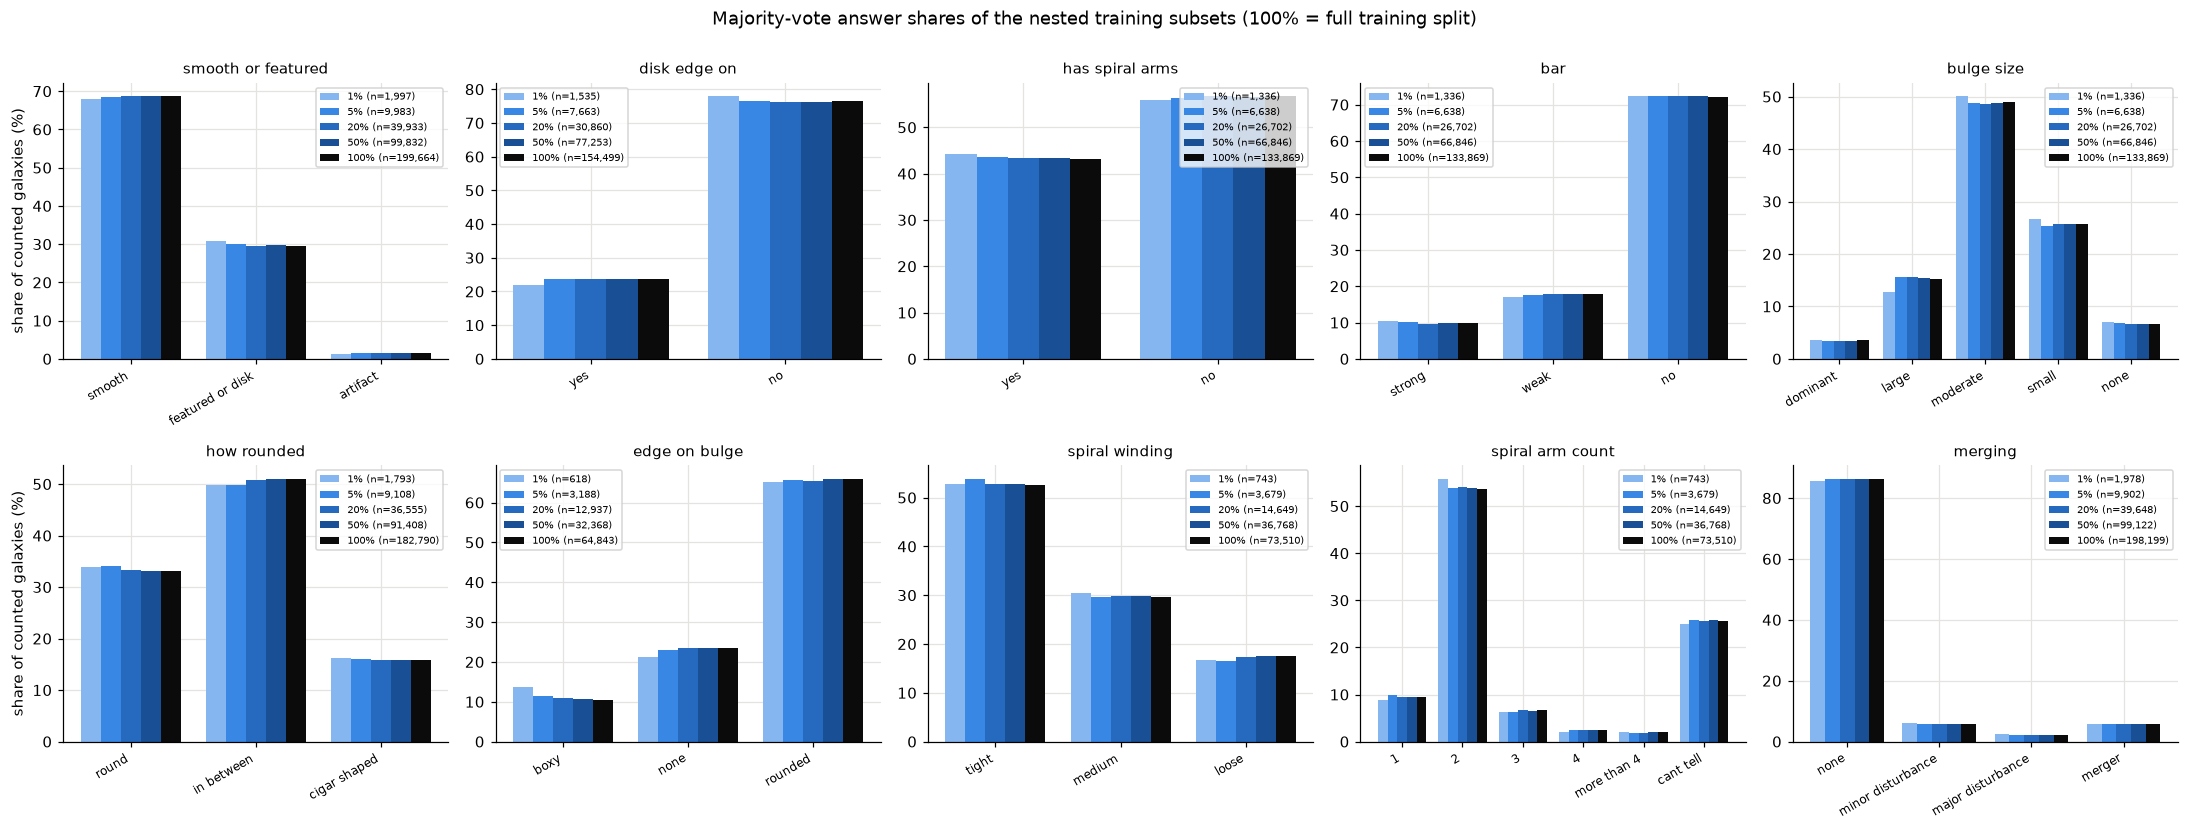

In [9]:
rep_rows = []
for g in [k for k in SUBSET_COUNTS if k != "100%"]:
    for q in GZD5_QUESTIONS:
        n_sub, c_sub = SUBSET_COUNTS[g][q.name]
        n_all, c_all = SUBSET_COUNTS["100%"][q.name]
        for k, a in enumerate(q.answers):
            p, p0 = c_sub[k] / n_sub, c_all[k] / n_all
            se = np.sqrt(p0 * (1 - p0) / n_sub * (n_all - n_sub) / max(n_all - 1, 1))
            rep_rows.append({"subset": g, "question": q.name, "answer": a, "n counted": n_sub,
                             "share subset %": 100 * p, "share train %": 100 * p0,
                             "gap pp": 100 * (p - p0), "z": (p - p0) / se if se > 0 else 0.0})
rep_df = pd.DataFrame(rep_rows)
rep_summary = rep_df.groupby("subset", sort=False).agg(
    max_gap_pp=("gap pp", lambda x: x.abs().max()),
    max_abs_z=("z", lambda x: x.abs().max()),
    n_abs_z_gt_2=("z", lambda x: int((x.abs() > 2).sum())),
    n_abs_z_gt_3=("z", lambda x: int((x.abs() > 3).sum())),
    answers=("z", "size"))
worst = rep_df.loc[rep_df.groupby("subset", sort=False)["gap pp"].apply(lambda x: x.abs().idxmax())]
rep_summary["largest gap at"] = (worst["question"] + ": " + worst["answer"]).to_numpy()
display(Markdown("**Subset answer shares vs the full training split**"))
display(rep_summary.round(2))
display(Markdown("**Answers with |z| > 2** (expected ≈ 1.7 per subset by chance)"))
display(rep_df[rep_df["z"].abs() > 2].round(2).reset_index(drop=True))
rep_df.to_csv(TABLE_DIR / "subset_representativeness.csv", index=False)

# LaTeX summary for the paper
lines = [r"\begin{table}", r"\centering",
         r"\caption{Representativeness of the training subsets: largest difference between a subset's majority-answer "
         r"share and that of the full training split over all 34 answers, and the number of answers deviating by "
         r"more than 2 or 3 standard errors of random sampling (about 1.7 beyond $2\sigma$ are expected by chance).}",
         r"\label{tab:subset_representativeness}", r"\begin{tabular}{rrrrr}", r"\toprule",
         r"Subset & Largest gap (pp) & Max $|z|$ & $|z|>2$ & $|z|>3$ \\", r"\midrule"]
for g, r in rep_summary.iterrows():
    lines.append(f"{g.replace('%', chr(92) + '%')} & {r['max_gap_pp']:.2f} & {r['max_abs_z']:.2f} & "
                 f"{int(r['n_abs_z_gt_2'])} & {int(r['n_abs_z_gt_3'])} \\\\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
(TABLE_DIR / "subset_representativeness.tex").write_text("\n".join(lines) + "\n")

# figure: answer shares of every subset next to the full training split
SUB_COLORS = dict(zip(SUBSET_COUNTS, ["#86b6ef", "#3987e5", "#256abf", "#184f95", "#0b0b0b"]))
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, q in zip(axes.flat, GZD5_QUESTIONS):
    x = np.arange(len(q.answers))
    w = 0.8 / len(SUBSET_COUNTS)
    for i, (g, mc) in enumerate(SUBSET_COUNTS.items()):
        n_q, c = mc[q.name]
        ax.bar(x + (i - (len(SUBSET_COUNTS) - 1) / 2) * w, 100 * c / n_q, width=w, color=SUB_COLORS[g],
               label=f"{g} (n={n_q:,})")
    ax.set_xticks(x, [ALABEL(a) for a in q.answers], rotation=30, ha="right", fontsize=8)
    ax.set_title(QLABEL[q.name], fontsize=10)
    ax.legend(fontsize=6.5)
for ax in axes[:, 0]:
    ax.set_ylabel("share of counted galaxies (%)")
fig.suptitle("Majority-vote answer shares of the nested training subsets (100% = full training split)", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "answer_shares_per_subset.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG_DIR / "answer_shares_per_subset.pdf", bbox_inches="tight")
plt.show()

In [10]:
# sizes table for the paper: subsets
lines = [r"\begin{table}", r"\centering",
         r"\caption{Training subsets of the training-set-size sweep. Subsets are fixed and nested, and shared by all "
         r"experiments and seeds. Checkpoints are selected on a fixed subset of 5{,}000 validation galaxies and "
         r"scored on the full test split.}",
         r"\label{tab:subsets}", r"\begin{tabular}{rr}", r"\toprule", r"Fraction & Training galaxies \\", r"\midrule"]
lines += [f"{100 * f:g}\\% & {num(len(SUBSETS[f]))} \\\\" for f in fr]
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
tex = "\n".join(lines)
(TABLE_DIR / "train_subsets.tex").write_text(tex + "\n")
print(tex)
print(f"\ntables in {TABLE_DIR}/: " + ", ".join(sorted(p.name for p in TABLE_DIR.iterdir())))

\begin{table}
\centering
\caption{Training subsets of the training-set-size sweep. Subsets are fixed and nested, and shared by all experiments and seeds. Checkpoints are selected on a fixed subset of 5{,}000 validation galaxies and scored on the full test split.}
\label{tab:subsets}
\begin{tabular}{rr}
\toprule
Fraction & Training galaxies \\
\midrule
1\% & 1{,}997 \\
5\% & 9{,}983 \\
20\% & 39{,}933 \\
50\% & 99{,}832 \\
100\% & 199{,}664 \\
\bottomrule
\end{tabular}
\end{table}

tables in results/tables/dataset/: morphology_per_split.csv, morphology_per_split.tex, morphology_train_subsets.csv, morphology_train_subsets.tex, splits.csv, splits.tex, subset_representativeness.csv, subset_representativeness.tex, train_subsets.tex
